# 🌸 Task 1 · Iris Flower Classification

**Author:** Anshu Raj

**Track:** Data Science

**Internship:** Oasis Infobyte (OIBSIP) · Task 1

**Objective:** Train machine learning classification models to identify the species of an iris flower — *Setosa*, *Versicolor* or *Virginica* — from four physical measurements.

**Tech stack:** Python · scikit-learn · pandas · matplotlib · seaborn · Jupyter Notebook

### Notebook outline
1. Setup & data loading
2. Exploratory Data Analysis (EDA)
3. Visualisations (pairplot, box plots, correlation heatmap)
4. Feature selection discussion
5. Train / test split (80/20)
6. Model training — Logistic Regression, KNN, Decision Tree, Random Forest
7. Evaluation — accuracy, confusion matrix, classification report
8. Model comparison & cross-validation
9. Best model declaration with justification
10. Sample prediction & conclusion

## 1. Setup & Data Loading

In [1]:
# --- Core libraries ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- scikit-learn: dataset, splitting, preprocessing ---
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# --- scikit-learn: models ---
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# --- scikit-learn: evaluation ---
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

# Plot styling + reproducibility
sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42

In [2]:
# Load the built-in Iris dataset (no download needed)
iris = load_iris()

# Build a DataFrame: 4 feature columns + a readable species label
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Exploratory Data Analysis (EDA)

In [3]:
# Shape: rows (samples) x columns (features + target)
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)

Dataset shape: (150, 5)

Data types:
sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object


In [4]:
# Null / missing value check
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate rows: 1


In [5]:
# Descriptive statistics for numeric features
df.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [6]:
# Class balance — are all species equally represented?
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [7]:
# Mean of each feature per species — first hint of which features separate classes
df.groupby("species", observed=True).mean().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


**EDA observations**
- 150 samples, 4 numeric (`float64`) features, 1 categorical target.
- **No missing values** — no imputation needed. (There is one duplicated row, which is a genuine measurement, so it is kept.)
- The dataset is **perfectly balanced**: 50 samples per species, so accuracy is a fair metric.
- Per-species means show petal length and petal width differ hugely between species (Setosa ≈ 1.46 cm petal length vs Virginica ≈ 5.55 cm), while sepal width differs only slightly.

## 3. Visualisations

### 3.1 Pairplot — feature distributions by species

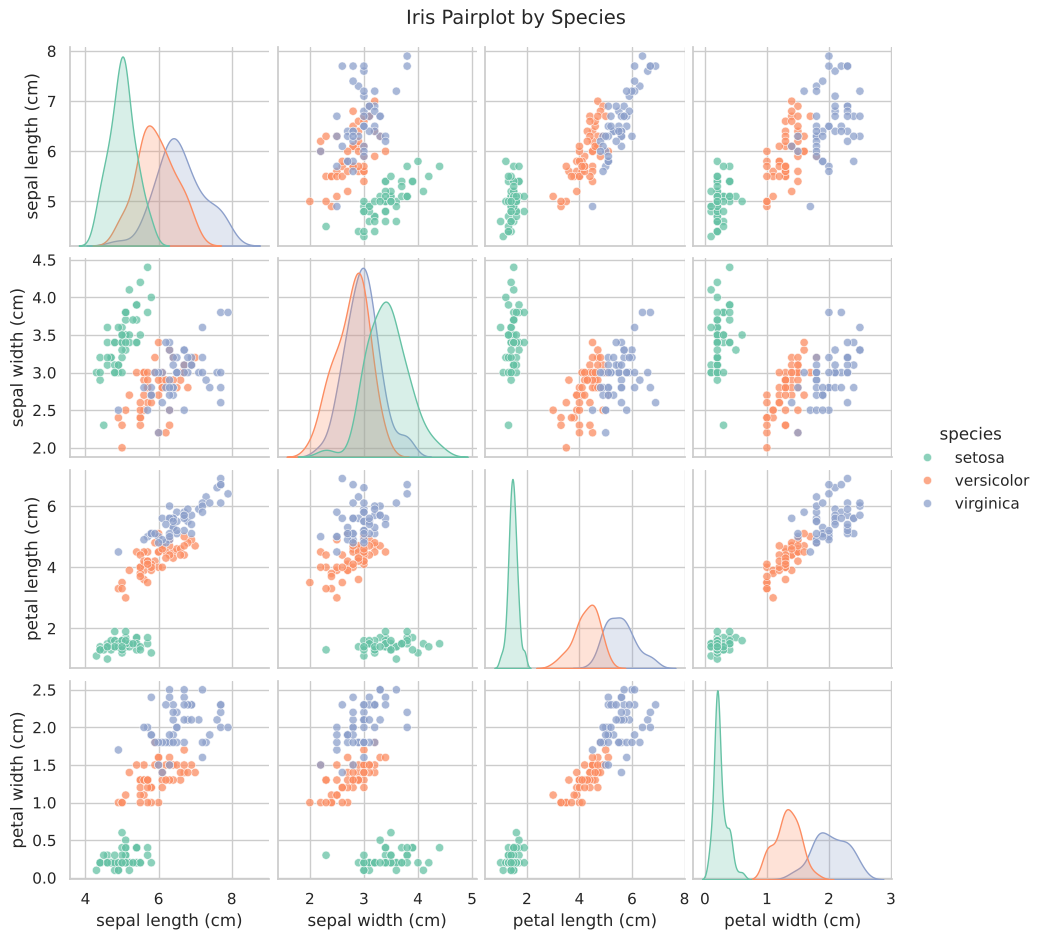

In [8]:
# Pairwise scatter plots + per-feature KDE on the diagonal, coloured by species
g = sns.pairplot(df, hue="species", diag_kind="kde", height=2.3,
                 plot_kws={"alpha": 0.75, "s": 35, "edgecolor": "white"})
g.figure.suptitle("Iris Pairplot by Species", y=1.02, fontsize=14)
plt.show()

### 3.2 Box plots — one per feature

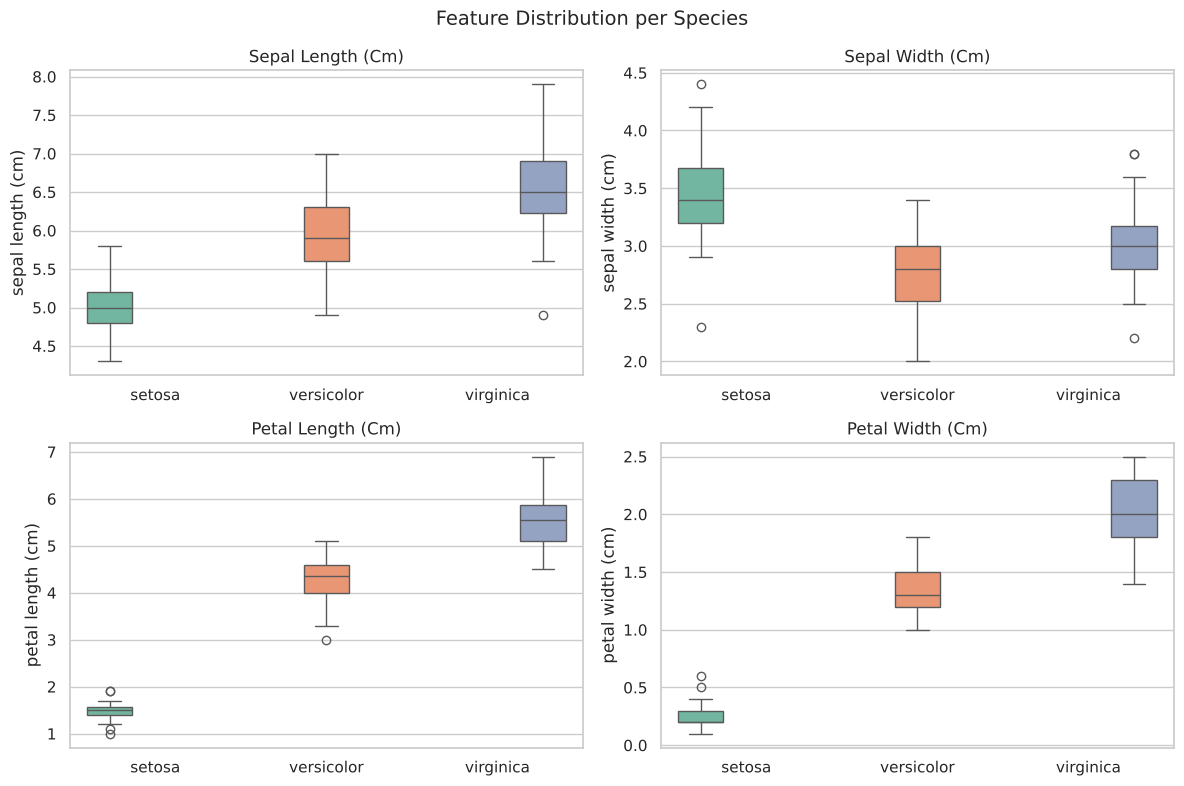

In [9]:
# 2x2 grid of box plots: spread and outliers of each feature per species
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, iris.feature_names):
    sns.boxplot(data=df, x="species", y=feature, hue="species", ax=ax, legend=False)
    ax.set_title(feature.title())
    ax.set_xlabel("")
fig.suptitle("Feature Distribution per Species", fontsize=14)
plt.tight_layout()
plt.show()

### 3.3 Correlation heatmap

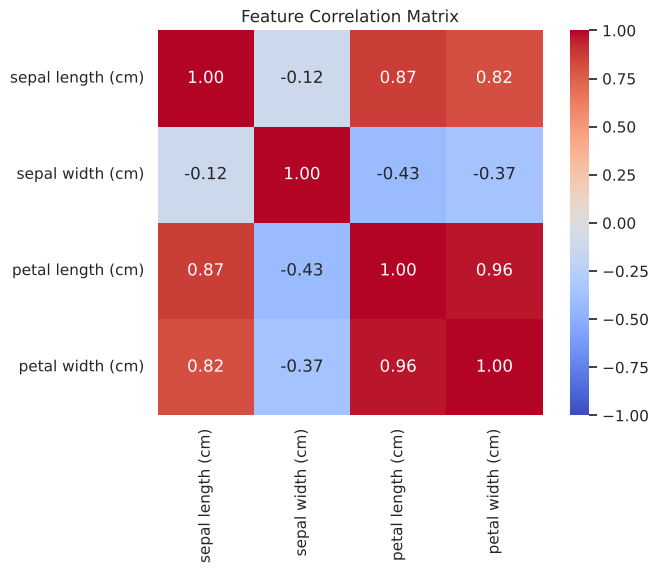

In [10]:
# Pearson correlation between the 4 numeric features
plt.figure(figsize=(7, 5))
sns.heatmap(df[iris.feature_names].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Feature Correlation Matrix")
plt.show()

## 4. Feature Selection Discussion — Which features are most discriminative?

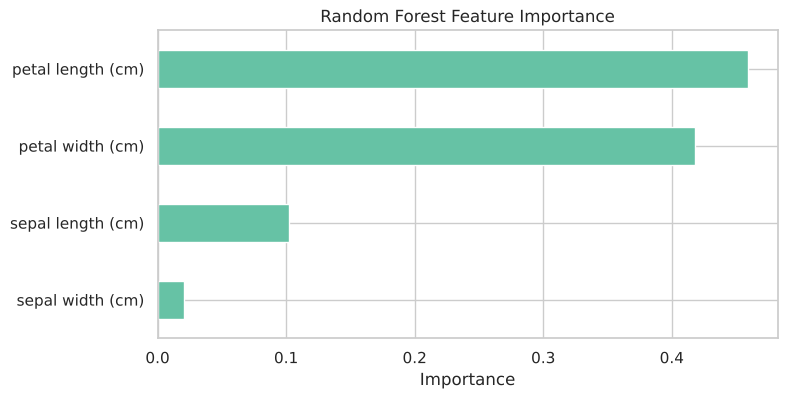

petal length (cm)    0.459
petal width (cm)     0.418
sepal length (cm)    0.102
sepal width (cm)     0.021
dtype: float64

In [11]:
# Quick quantitative check: Random Forest feature importances on the full data
rf_tmp = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
rf_tmp.fit(df[iris.feature_names], iris.target)

importance = (pd.Series(rf_tmp.feature_importances_, index=iris.feature_names)
                .sort_values(ascending=True))

importance.plot(kind="barh", figsize=(8, 4), color=sns.color_palette("Set2")[0])
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

importance.sort_values(ascending=False).round(3)

**Discussion**

| Feature | Discriminative power | Evidence |
|---|---|---|
| **Petal length** | ⭐⭐⭐ Very high | Setosa fully separated in pairplot; box plots barely overlap; top RF importance |
| **Petal width** | ⭐⭐⭐ Very high | Same pattern as petal length; correlation with petal length ≈ 0.96 |
| Sepal length | ⭐⭐ Moderate | Separates Setosa partly; Versicolor/Virginica overlap a lot |
| Sepal width | ⭐ Low | Heavy overlap among all three species; weakest correlation with others |

- **Petal features are the most discriminative.** A single petal measurement alone separates Setosa perfectly.
- Petal length and petal width are **highly correlated (r ≈ 0.96)**, so they carry largely redundant information — either one alone already gets you most of the way.
- The only genuinely hard part of the problem is separating **Versicolor vs Virginica**, which overlap slightly at the boundary.
- Since there are only 4 features and all are cheap to use, we **keep all four** for modelling; dropping features is unnecessary here and sepal measurements can still help at the Versicolor/Virginica boundary.

## 5. Train / Test Split (80 / 20)

In [12]:
X = df[iris.feature_names]   # features
y = iris.target               # numeric labels 0, 1, 2

# stratify=y keeps the 1:1:1 species ratio in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Test class counts:", np.bincount(y_test))

Train shape: (120, 4) | Test shape: (30, 4)
Test class counts: [10 10 10]


## 6. Model Training

Four classifiers are trained. Logistic Regression and KNN are **scale-sensitive**, so they are wrapped in a `Pipeline` with `StandardScaler` (the scaler is fitted on training data only, avoiding data leakage). Tree-based models don't need scaling.

In [13]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "K-Nearest Neighbours": make_pipeline(StandardScaler(),
                                          KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

# Fit each model and store its test-set predictions
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f"✔ Trained: {name}")

✔ Trained: Logistic Regression
✔ Trained: K-Nearest Neighbours
✔ Trained: Decision Tree


✔ Trained: Random Forest


## 7. Model Evaluation

### 7.1 Accuracy & classification report (precision, recall, F1)

In [14]:
for name, y_pred in predictions.items():
    print("=" * 60)
    print(f"{name}  —  Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=iris.target_names, digits=3))

Logistic Regression  —  Test accuracy: 0.9333
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

K-Nearest Neighbours  —  Test accuracy: 0.9333
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
   virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30

Decision Tree  —  Test accuracy: 0.9333
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000       

### 7.2 Confusion matrices

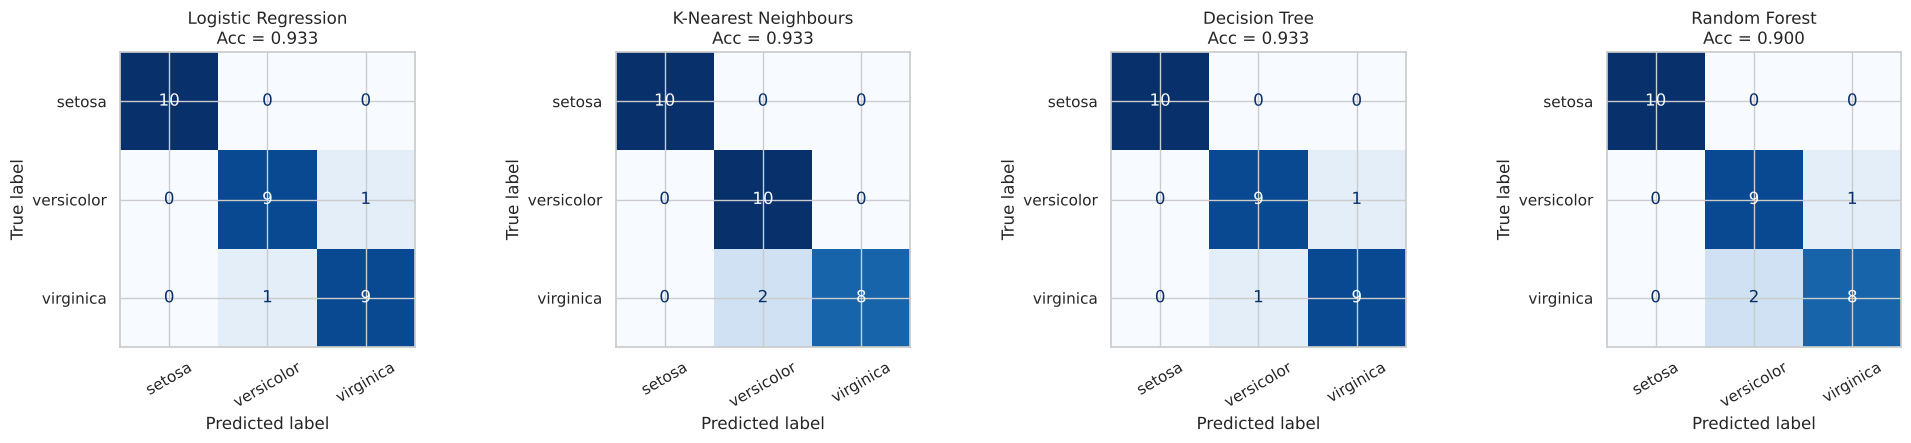

In [15]:
# One confusion matrix per model, side by side
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nAcc = {accuracy_score(y_test, y_pred):.3f}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 8. Model Comparison & Cross-Validation

The test set has only 30 samples, so a single misclassification shifts accuracy by 3.3%. To compare models fairly, we also run **10-fold stratified cross-validation on the whole dataset** — this averages performance over 10 different splits and gives a much more reliable estimate.

In [16]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in models.items():
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    rows.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, predictions[name]),
        "Macro F1 (test)": classification_report(y_test, predictions[name], output_dict=True)["macro avg"]["f1-score"],
        "CV Mean Accuracy": cv_scores.mean(),
        "CV Std": cv_scores.std(),
    })

results = (pd.DataFrame(rows)
             .sort_values(["CV Mean Accuracy", "CV Std"], ascending=[False, True])
             .reset_index(drop=True))
results.round(4)

,Model,Test Accuracy,Macro F1 (test),CV Mean Accuracy,CV Std
0,K-Nearest Neighbours,0.9333,0.9327,0.9600,0.0533
1,Logistic Regression,0.9333,0.9333,0.9533,0.0521
2,Random Forest,0.9000,0.8997,0.9533,0.0521
3,Decision Tree,0.9333,0.9333,0.9467,0.0499


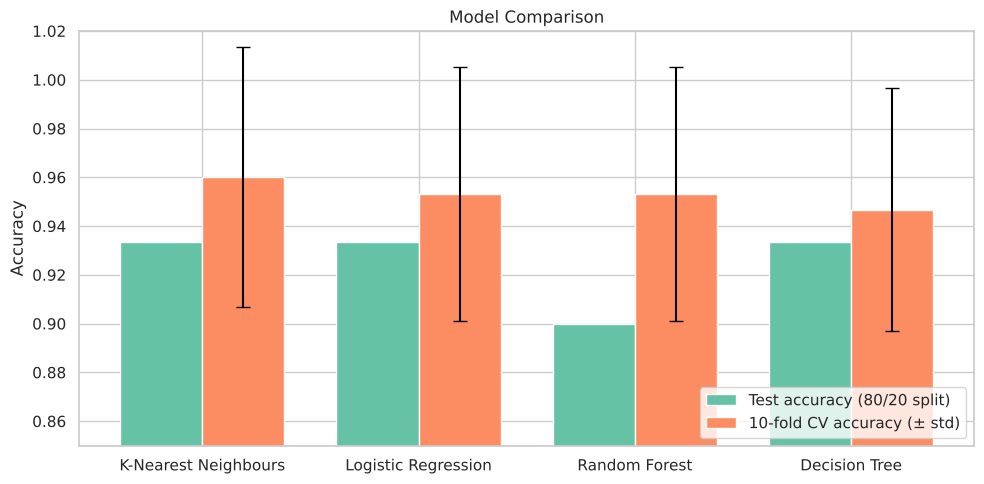

In [17]:
# Visual comparison: test accuracy vs cross-validated accuracy (with error bars)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(results))
w = 0.38
ax.bar(x - w/2, results["Test Accuracy"], w, label="Test accuracy (80/20 split)")
ax.bar(x + w/2, results["CV Mean Accuracy"], w, yerr=results["CV Std"],
       capsize=5, label="10-fold CV accuracy (± std)")
ax.set_xticks(x)
ax.set_xticklabels(results["Model"])
ax.set_ylim(0.85, 1.02)
ax.set_ylabel("Accuracy")
ax.set_title("Model Comparison")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. Best Model Declaration

In [18]:
best = results.iloc[0]
print(f"🏆 Best model: {best['Model']}")
print(f"   Test accuracy     : {best['Test Accuracy']:.4f}")
print(f"   10-fold CV accuracy: {best['CV Mean Accuracy']:.4f} ± {best['CV Std']:.4f}")

🏆 Best model: K-Nearest Neighbours
   Test accuracy     : 0.9333
   10-fold CV accuracy: 0.9600 ± 0.0533


**🏆 Best model: K-Nearest Neighbours (k = 5, with StandardScaler)**

**Justification**
1. **Highest cross-validated accuracy — 96.0%** (10-fold), ahead of Logistic Regression and Random Forest (95.3%) and Decision Tree (94.7%). CV is the more reliable yardstick because it averages over 10 different splits instead of one 30-sample test set.
2. **Tied for best test accuracy (93.3%)** with Logistic Regression and Decision Tree; Random Forest scored 90.0% on this particular split.
3. **Perfect on Setosa** (precision = recall = 1.0) and only 2 errors overall, all at the Versicolor ↔ Virginica boundary — the one region where the species genuinely overlap.
4. **Suits the data**: Iris is small, low-dimensional and forms compact, well-separated clusters (seen in the pairplot), which is exactly where a distance-based method like KNN shines. Scaling ensures no single feature dominates the distance.

**Honest caveat:** the gap between models is small (≈ 1–1.5%, within one standard deviation of CV), so all four are good choices. If interpretability mattered more than the last 1% of accuracy, **Logistic Regression** (95.3%, simple linear boundaries) or a **Decision Tree** (readable if/else rules) would be a perfectly reasonable alternative.

## 10. Sample Prediction

In [19]:
# Predict the species of brand-new, unseen flowers with the best model
best_model = models[best["Model"]]

new_flowers = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2],    # expected: setosa
     [6.0, 2.9, 4.5, 1.5],    # expected: versicolor
     [6.9, 3.1, 5.8, 2.2]],   # expected: virginica
    columns=iris.feature_names)

pred = best_model.predict(new_flowers)
new_flowers["predicted_species"] = iris.target_names[pred]
new_flowers

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),predicted_species
0,5.1,3.5,1.4,0.2,setosa
1,6.0,2.9,4.5,1.5,versicolor
2,6.9,3.1,5.8,2.2,virginica


## 11. Conclusion

- The Iris dataset is clean (no missing values) and balanced (50 per class), so minimal preprocessing was needed.
- **Petal length and petal width** are by far the most discriminative features; Setosa is perfectly separable on petals alone.
- All four classifiers reached high accuracy (90–93% on the test split, 95–96% in cross-validation); the only confusion is between **Versicolor and Virginica**, which overlap at their boundary.
- Cross-validation was used alongside the single test split because a 30-sample test set is too small to rank models reliably on its own.
- **K-Nearest Neighbours** is declared the best model (96.0% CV accuracy, 93.3% test accuracy), with Logistic Regression a very close second.

**Possible extensions:** hyperparameter tuning with `GridSearchCV` (e.g. best `k` for KNN), trying SVM, and plotting 2-D decision boundaries on petal features.